# Phase 2 Pre-check

classical models only, no circuits. it answers four questions before the big runs:

1. pls: how much do 8, 16 and 32 pls components give, and is there anything for a feature search to find among them?
2. 16 inputs on 8 qubits: does reading two numbers per qubit help, for pca and pls?
3. raw clip: can 8 of the raw clip numbers (512 for ViT-B/16, 768 for ViT-L/14), picked by aco, greedy or random search, compete with pca and pls?
4. one summary table.

set `encoder` in the next cell: "b16" is the phase 1 encoder, "l14" the larger ViT-L/14. everything else is the same for both.

every circuit without entanglers equals its classical twin, so the twin tells us what a circuit can reach on each input. same rules as phase 1: picking uses search-train and the inner fitness split only, val is used for the final numbers.

In [1]:
import os
# one thread per process, set before numpy loads
os.environ["OMP_NUM_THREADS"] = "1"
import time
import json
import multiprocessing as mp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.cross_decomposition import PLSRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score

seed = 0
np.random.seed(seed)

encoder = "l14"   # "b16" or "l14"
if encoder == "b16":
    prep_dir = "/kaggle/input/datasets/malakkhaled202300369/nic-feature-dataset/prep"
    clip_dir = "/kaggle/input/datasets/malakkhaled202300369/nic-clip-dataset/features"
else:
    prep_dir = "/kaggle/input/datasets/malakkhaled202300369/nic-768featues-prep/prep_l14"
    clip_dir = "/kaggle/input/datasets/malakkhaled202300369/nic-clip768-l14-dataset/features_l14"
out_dir = f"/kaggle/working/precheck_{encoder}"
os.makedirs(out_dir, exist_ok=True)

c_grid = [0.01, 0.1, 1.0]   # logistic regression strength, picked on val like the phase 1 baselines
n_pls = 32
low, high = 0.5, 99.5       # angle range from search-train percentiles, same as phase 1
# raw clip search
n_runs = 3
pop_size = 20               # ants per round, random subsets per round
top_k = 3
rho = 0.1
tau_min = 0.1
tau_max = 5.0
hint_power = 1.0            # aco with hint: chance ~ pheromone x (strength - 0.5)

In [2]:
angles, meta = {}, {}
for split in ["train", "val"]:
    angles[split] = np.load(f"{prep_dir}/ffpp_{split}_angles32.npy").astype(np.float64)
    meta[split] = pd.read_csv(f"{prep_dir}/ffpp_{split}_rows.csv")

is_inner = np.load(f"{prep_dir}/ffpp_train_is_inner.npy").astype(bool)
comp = pd.read_csv(f"{prep_dir}/per_component_auc.csv")
pca_order = comp.sort_values("strength_search_train", ascending=False)["component"].tolist()
first8 = list(range(8))
best8 = sorted(pca_order[:8])

clip = {}
for split in ["train", "val"]:
    clip_rows = pd.read_csv(f"{clip_dir}/ffpp_{split}_rows.csv")
    assert (clip_rows["path"].to_numpy() == meta[split]["path"].to_numpy()).all(), split
    x = np.load(f"{clip_dir}/ffpp_{split}_clip.npy").astype(np.float64)
    clip[split] = x / np.linalg.norm(x, axis=1, keepdims=True)

y_train = meta["train"]["label"].to_numpy()
y_val = meta["val"]["label"].to_numpy()
# a video is (method, video_id), the 4 fakes of one pair share a video_id
val_video = meta["val"].groupby(["method", "video_id"]).ngroup().to_numpy()
st = ~is_inner
n_raw = clip["train"].shape[1]
budget = 8 * n_raw          # distinct subsets per run, about what greedy on all raw numbers costs

print("train frames:", len(y_train), " search-train:", st.sum(), " inner:", is_inner.sum(), " val videos:", val_video.max() + 1)
print("encoder:", encoder, " clip numbers per face:", n_raw, " search budget:", budget)

train frames: 46076  search-train: 39164  inner: 6912  val videos: 700
encoder: l14  clip numbers per face: 768  search budget: 6144


## fitness frames

same 2000 frames as the phase 1 search (1000 real, 1000 fake, at most 2 per real video and 1 per fake video), scored on the inner fitness frames.

In [3]:
search_idx = np.where(~is_inner)[0]
inner_idx = np.where(is_inner)[0]

st_rows = meta["train"].iloc[search_idx].copy()
st_rows["row"] = search_idx
real_pick = st_rows[st_rows["label"] == 0].groupby("video_id").sample(n=2, random_state=0)["row"].to_numpy()
fake_pick = st_rows[st_rows["label"] == 1].groupby(["method", "video_id"]).sample(n=1, random_state=0)["row"].to_numpy()
rng = np.random.default_rng(0)
sub = np.concatenate([rng.choice(real_pick, 1000, replace=False), rng.choice(fake_pick, 1000, replace=False)])

## helpers

the same scoring as phase 1, plus the twin for two numbers per qubit. a qubit that gets RY(a) then RZ(b) has the bloch vector (sin a cos b, sin a sin b, cos a), and after any trainable rotation its <z> is a linear function of those 3 numbers. so that circuit's twin is logistic regression on 3 features per qubit. qubit q gets inputs q and q + 8.

In [4]:
def video_level(prob):
    df = pd.DataFrame({"video": val_video, "p": prob, "y": y_val})
    g = df.groupby("video").agg(p=("p", "mean"), y=("y", "first"))
    return g["p"].to_numpy(), g["y"].to_numpy()


def bootstrap_ci(p, y, n=1000, seed=0):
    rng = np.random.default_rng(seed)
    aucs = []
    while len(aucs) < n:
        idx = rng.integers(0, len(y), len(y))
        if y[idx].min() == y[idx].max():
            continue
        aucs.append(roc_auc_score(y[idx], p[idx]))
    return np.percentile(aucs, [2.5, 97.5])


def score(prob):
    pv, yv = video_level(prob)
    lo, hi = bootstrap_ci(pv, yv)
    return {"frame auc": roc_auc_score(y_val, prob), "video auc": roc_auc_score(yv, pv), "ci low": lo, "ci high": hi}


def sincos(a):
    return np.concatenate([np.sin(a), np.cos(a)], axis=1)


def bloch(a):
    # 16 angles on 8 qubits: qubit q gets RY(a[q]) then RZ(a[q + 8])
    ay, az = a[:, :8], a[:, 8:16]
    return np.concatenate([np.sin(ay) * np.cos(az), np.sin(ay) * np.sin(az), np.cos(ay)], axis=1)


def logreg(c):
    return make_pipeline(StandardScaler(), LogisticRegression(C=c, max_iter=5000))


def to_angles(z_train, z_val):
    # range from search-train only
    lo = np.percentile(z_train[st], low, axis=0)
    hi = np.percentile(z_train[st], high, axis=0)
    return {"train": np.clip((z_train - lo) / (hi - lo), 0.0, 1.0) * np.pi,
            "val": np.clip((z_val - lo) / (hi - lo), 0.0, 1.0) * np.pi}


def strengths(z_train):
    # each column's own auc on search-train, either direction
    out = []
    for j in range(z_train.shape[1]):
        auc = roc_auc_score(y_train[st], z_train[st, j])
        out.append(max(auc, 1 - auc))
    return np.array(out)


table = []


def tune(part, inp, model, xt, xv, weights):
    # one fit per setting on all of train, keep the best val video auc
    best = None
    for c in c_grid:
        prob = logreg(c).fit(xt, y_train).predict_proba(xv)[:, 1]
        pv, yv = video_level(prob)
        auc = roc_auc_score(yv, pv)
        if best is None or auc > best[1]:
            best = (c, auc, prob)
    row = {"part": part, "input": inp, "model": model, "weights": weights, "setting": best[0]}
    row.update(score(best[2]))
    table.append(row)
    print(f"{inp:28s} {model:22s} video auc {row['video auc']:.3f} ({row['ci low']:.3f} to {row['ci high']:.3f})")
    return row


def greedy(a, k, fit_rows, score_rows, label):
    # adds the column that most raises the twin's auc, phase 1 rule (C = 1)
    selected, n_fits = [], 0
    for step in range(k):
        best = None
        for j in range(a.shape[1]):
            if j in selected:
                continue
            cols = selected + [j]
            model = logreg(1.0).fit(sincos(a[fit_rows][:, cols]), y_train[fit_rows])
            auc = roc_auc_score(y_train[score_rows], model.predict_proba(sincos(a[score_rows][:, cols]))[:, 1])
            n_fits += 1
            if best is None or auc > best[1]:
                best = (j, auc)
        selected.append(best[0])
    print(f"greedy on {label}: added in order {selected}, inner auc {best[1]:.3f}, {n_fits} fits")
    return selected, n_fits

## part 1: pls

pls fitted with 32 components on search-train only, so neither the inner split nor val is seen. pls builds its components one after another, so its first 8 are the same as an 8-component fit.

In [5]:
pls = PLSRegression(n_components=n_pls, scale=False)
pls.fit(clip["train"][st], y_train[st])
pls_a = to_angles(pls.transform(clip["train"]), pls.transform(clip["val"]))

pls_strength = strengths(pls_a["train"])
pls_comp = pd.DataFrame({"component": range(n_pls), "strength_search_train": pls_strength})
pls_comp.to_csv(f"{out_dir}/pls_per_component_auc.csv", index=False)
print("pls strength, first 8: ", np.round(pls_strength[:8], 3))
print("pls strength, 9 to 16: ", np.round(pls_strength[8:16], 3))
print("pls strength, 17 to 32 max:", round(pls_strength[16:].max(), 3))

pls strength, first 8:  [0.758 0.656 0.566 0.589 0.586 0.595 0.571 0.572]
pls strength, 9 to 16:  [0.557 0.553 0.556 0.546 0.549 0.537 0.535 0.536]
pls strength, 17 to 32 max: 0.532


In [6]:
at, av = pls_a["train"], pls_a["val"]
tune("pls", "pls 8", "logistic regression", at[:, :8], av[:, :8], 9)
tune("pls", "pls 8", "sin/cos twin", sincos(at[:, :8]), sincos(av[:, :8]), 17)
tune("pls", "pls 16", "logistic regression", at[:, :16], av[:, :16], 17)
tune("pls", "pls 16 on 8 qubits", "2-per-qubit twin", bloch(at[:, :16]), bloch(av[:, :16]), 25)
tune("pls", "pls 32", "logistic regression", at, av, 33)

pls 8                        logistic regression    video auc 0.890 (0.863 to 0.916)
pls 8                        sin/cos twin           video auc 0.892 (0.866 to 0.917)
pls 16                       logistic regression    video auc 0.896 (0.868 to 0.921)
pls 16 on 8 qubits           2-per-qubit twin       video auc 0.893 (0.865 to 0.919)
pls 32                       logistic regression    video auc 0.896 (0.869 to 0.921)


{'part': 'pls',
 'input': 'pls 32',
 'model': 'logistic regression',
 'weights': 33,
 'setting': 0.01,
 'frame auc': np.float64(0.8659464156141359),
 'video auc': np.float64(0.8961734693877552),
 'ci low': np.float64(0.8688869165401844),
 'ci high': np.float64(0.9210121938307269)}

## greedy over the 32 pls components

the phase 1 greedy rule: the twin trained on search-train, scored on the inner split. if greedy mostly picks the first 8, a feature search on pls has little to find.

In [7]:
pls_greedy, _ = greedy(pls_a["train"], 8, st, is_inner, "32 pls")
pls_greedy8 = sorted(pls_greedy)
print("of the greedy 8, in the first 8:", sum(j < 8 for j in pls_greedy8))
tune("pls", f"pls greedy 8 {pls_greedy8}", "sin/cos twin", sincos(at[:, pls_greedy8]), sincos(av[:, pls_greedy8]), 17)

greedy on 32 pls: added in order [0, 1, 3, 5, 4, 2, 6, 8], inner auc 0.865, 228 fits
of the greedy 8, in the first 8: 7
pls greedy 8 [0, 1, 2, 3, 4, 5, 6, 8] sin/cos twin           video auc 0.875 (0.848 to 0.900)


{'part': 'pls',
 'input': 'pls greedy 8 [0, 1, 2, 3, 4, 5, 6, 8]',
 'model': 'sin/cos twin',
 'weights': 17,
 'setting': 0.01,
 'frame auc': np.float64(0.8500763732736899),
 'video auc': np.float64(0.8754336734693876),
 'ci low': np.float64(0.8480488135250775),
 'ci high': np.float64(0.9001931874589141)}

## part 2: 16 inputs on 8 qubits, pca

the 8-input rows repeat phase 1 for comparison (for b16 the greedy 8 should come out as [3, 4, 8, 9, 10, 16, 17, 21] again). best 16 are the 16 strongest components on search-train.

In [8]:
at, av = angles["train"], angles["val"]
pca_greedy, _ = greedy(at, 8, st, is_inner, "32 pca")
greedy8 = sorted(pca_greedy)
best16 = pca_order[:16]
first16 = list(range(16))
for label, cols in [("pca first 8", first8), ("pca best 8", best8), ("pca greedy 8", greedy8)]:
    tune("pca", label, "sin/cos twin", sincos(at[:, cols]), sincos(av[:, cols]), 17)
for label, cols in [("pca first 16", first16), ("pca best 16", best16)]:
    tune("pca", label, "logistic regression", at[:, cols], av[:, cols], 17)
    tune("pca", label + " on 8 qubits", "2-per-qubit twin", bloch(at[:, cols]), bloch(av[:, cols]), 25)

greedy on 32 pca: added in order [1, 5, 2, 11, 8, 28, 7, 29], inner auc 0.780, 228 fits
pca first 8                  sin/cos twin           video auc 0.738 (0.698 to 0.775)
pca best 8                   sin/cos twin           video auc 0.779 (0.744 to 0.816)
pca greedy 8                 sin/cos twin           video auc 0.772 (0.738 to 0.806)
pca first 16                 logistic regression    video auc 0.792 (0.755 to 0.829)
pca first 16 on 8 qubits     2-per-qubit twin       video auc 0.780 (0.745 to 0.817)
pca best 16                  logistic regression    video auc 0.798 (0.763 to 0.832)
pca best 16 on 8 qubits      2-per-qubit twin       video auc 0.796 (0.762 to 0.830)


## part 3: raw clip, 8 of all

each of the raw clip numbers (after scaling the vector to length 1) gets its own angle range from search-train. best 8 are the 8 strongest numbers on their own.

In [9]:
raw_a = to_angles(clip["train"], clip["val"])
raw_strength = strengths(raw_a["train"])
pd.DataFrame({"dim": range(n_raw), "strength_search_train": raw_strength}).to_csv(f"{out_dir}/raw_per_dim_auc.csv", index=False)
raw_best8 = sorted(np.argsort(-raw_strength)[:8].tolist())
print("strongest single clip numbers:", np.round(np.sort(raw_strength)[::-1][:8], 3))
print("dims with strength above 0.6:", (raw_strength > 0.6).sum())

at, av = raw_a["train"], raw_a["val"]
tune("raw", f"raw best 8 {raw_best8}", "sin/cos twin", sincos(at[:, raw_best8]), sincos(av[:, raw_best8]), 17)

strongest single clip numbers: [0.711 0.669 0.649 0.647 0.645 0.642 0.641 0.635]
dims with strength above 0.6: 44
raw best 8 [164, 178, 283, 349, 463, 527, 537, 605] sin/cos twin           video auc 0.768 (0.728 to 0.805)


{'part': 'raw',
 'input': 'raw best 8 [164, 178, 283, 349, 463, 527, 537, 605]',
 'model': 'sin/cos twin',
 'weights': 17,
 'setting': 0.01,
 'frame auc': np.float64(0.7471940484164195),
 'video auc': np.float64(0.7675000000000001),
 'ci low': np.float64(0.7280739722967581),
 'ci high': np.float64(0.8053780219683744)}

## search on raw clip

fitness is the sin/cos twin (C = 1) trained on the 2000 fitness frames and scored by auc on the inner frames. it takes milliseconds, so every method gets `budget` distinct subsets per run, about what greedy costs (4000 for 512 numbers, 6000 for 768). greedy uses the same fitness, so all four are scored the same way.

- random: 8 distinct numbers, uniform.
- aco: each ant picks 8 numbers one at a time, chance set by pheromone. after each round pheromone evaporates, the round's best and the best so far each add 1, values stay between `tau_min` and `tau_max` (the phase 1 aco, mask part only). no hint.
- aco + hint: the same, with each number's chance also multiplied by its own strength minus 0.5 (search-train only). greedy uses this kind of information, so this is the fairer rival to greedy.

In [10]:
fit_a = raw_a["train"][sub]
inner_a = raw_a["train"][inner_idx]
y_fit = y_train[sub]
y_inner = y_train[inner_idx]
hint = np.maximum(raw_strength - 0.5, 1e-3) ** hint_power


def fitness(mask):
    model = logreg(1.0).fit(sincos(fit_a[:, mask]), y_fit)
    return roc_auc_score(y_inner, model.predict_proba(sincos(inner_a[:, mask]))[:, 1])


def evaluate(masks, cache, log, method, run, limit=budget):
    # a subset seen before costs nothing and is not counted
    n_new = 0
    fit = []
    for m in masks:
        key = tuple(sorted(m))
        if key not in cache and len(cache) < limit:
            cache[key] = fitness(list(key))
            log.append({"method": method, "run": run, "eval": len(cache), "mask": ".".join(map(str, key)), "fitness": cache[key]})
            n_new += 1
        fit.append(cache.get(key))
    return fit, n_new


def random_search(run):
    rng = np.random.default_rng(6000 + run)
    cache, log = {}, []
    while len(cache) < budget:
        masks = [rng.choice(n_raw, 8, replace=False).tolist() for _ in range(pop_size)]
        evaluate(masks, cache, log, "random", run)
    return cache, log


def aco(run, use_hint):
    method = "aco + hint" if use_hint else "aco"
    rng = np.random.default_rng(4000 + run)
    tau = np.ones(n_raw)
    cache, log = {}, []
    best = None
    stale = 0
    while len(cache) < budget:
        masks = []
        for _ in range(pop_size):
            w = tau * hint if use_hint else tau.copy()
            mask = []
            for _ in range(8):
                j = int(rng.choice(n_raw, p=w / w.sum()))
                mask.append(j)
                w[j] = 0
            masks.append(mask)
        fit, n_new = evaluate(masks, cache, log, method, run)
        round_best = None
        for f, m in zip(fit, masks):
            if f is not None and (round_best is None or f > round_best[0]):
                round_best = (f, m)
        if round_best is None:
            break
        if best is None or round_best[0] > best[0]:
            best = round_best
        tau *= 1 - rho
        tau[round_best[1]] += 1
        tau[best[1]] += 1
        tau = np.clip(tau, tau_min, tau_max)
        if n_new == 0:
            stale += 1
        else:
            stale = 0
        if stale >= 20:
            print(f"{method} run {run} stopped early at {len(cache)} subsets")
            break
    return cache, log


def run_job(job):
    method, run = job
    t0 = time.time()
    if method == "random":
        cache, log = random_search(run)
    else:
        cache, log = aco(run, method == "aco + hint")
    return method, run, cache, log, time.time() - t0

In [11]:
# greedy on the fitness frames, counted like the searches
t0 = time.time()
cache, glog = {}, []
selected = []
for step in range(8):
    cands = [selected + [j] for j in range(n_raw) if j not in selected]
    # greedy has no budget cap, its cost is reported instead
    fit, _ = evaluate(cands, cache, glog, "greedy", 0, limit=10 ** 6)
    selected = cands[int(np.argmax(fit))]
raw_greedy8 = sorted(selected)
print(f"greedy: {raw_greedy8}, inner auc {cache[tuple(raw_greedy8)]:.3f}, {len(cache)} subsets, {time.time() - t0:.0f} s")

jobs = [(m, r) for r in range(n_runs) for m in ["random", "aco", "aco + hint"]]
with mp.get_context("fork").Pool(os.cpu_count()) as pool:
    results = pool.map(run_job, jobs)

caches = {(m, r): c for m, r, c, _, _ in results}
log = pd.DataFrame(glog + [row for _, _, _, l, _ in results for row in l])
log.to_csv(f"{out_dir}/raw_search_log.csv", index=False)
for m, r, c, _, sec in results:
    print(f"{m:10s} run {r}: {len(c)} subsets, best inner auc {max(c.values()):.3f}, {sec:.0f} s")

greedy: [149, 178, 189, 282, 527, 605, 693, 752], inner auc 0.791, 6116 subsets, 66 s
random     run 0: 6144 subsets, best inner auc 0.742, 149 s
aco        run 0: 6144 subsets, best inner auc 0.762, 153 s
aco + hint run 0: 6144 subsets, best inner auc 0.787, 152 s
random     run 1: 6144 subsets, best inner auc 0.741, 149 s
aco        run 1: 6144 subsets, best inner auc 0.764, 135 s
aco + hint run 1: 6144 subsets, best inner auc 0.788, 135 s
random     run 2: 6144 subsets, best inner auc 0.735, 130 s
aco        run 2: 6144 subsets, best inner auc 0.767, 133 s
aco + hint run 2: 6144 subsets, best inner auc 0.788, 85 s


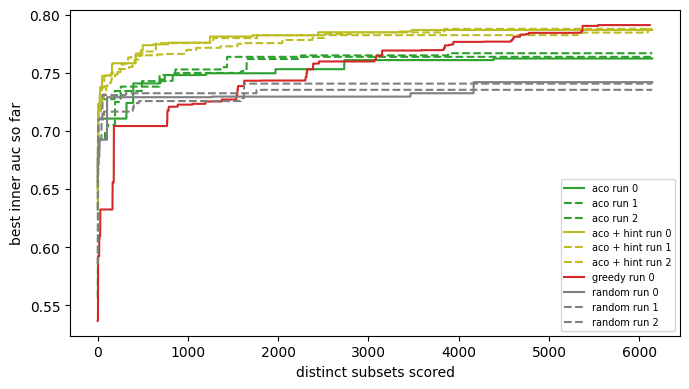

In [12]:
colors = {"random": "tab:gray", "aco": "tab:green", "aco + hint": "tab:olive", "greedy": "tab:red"}
plt.figure(figsize=(7, 4))
for (method, run), g in log.groupby(["method", "run"]):
    g = g.sort_values("eval")
    style = "-" if run == 0 else "--"
    plt.plot(g["eval"], g["fitness"].cummax(), style, color=colors[method], label=f"{method} run {run}")
plt.xlabel("distinct subsets scored")
plt.ylabel("best inner auc so far")
plt.legend(fontsize=7)
plt.tight_layout()
plt.savefig(f"{out_dir}/raw_convergence.png", dpi=150)
plt.show()

## final pick per run

each run's top 3 subsets get the twin trained on all of train, the best on val is the run's pick. greedy's 8 go through the same step.

In [13]:
at, av = raw_a["train"], raw_a["val"]
tune("raw", f"raw greedy 8 {raw_greedy8}", "sin/cos twin", sincos(at[:, raw_greedy8]), sincos(av[:, raw_greedy8]), 17)

picks = []
for (method, run), c in caches.items():
    top = sorted(c.items(), key=lambda t: t[1], reverse=True)[:top_k]
    best = None
    for key, inner_auc in top:
        cols = list(key)
        prob = logreg(1.0).fit(sincos(at[:, cols]), y_train).predict_proba(sincos(av[:, cols]))[:, 1]
        pv, yv = video_level(prob)
        auc = roc_auc_score(yv, pv)
        if best is None or auc > best[1]:
            best = (cols, auc, inner_auc)
    picks.append({"method": method, "run": run, "mask": best[0], "inner auc": best[2], "val video auc": best[1]})
    tune("raw", f"raw {method} run {run} {best[0]}", "sin/cos twin", sincos(at[:, best[0]]), sincos(av[:, best[0]]), 17)

picks = pd.DataFrame(picks)
picks.to_csv(f"{out_dir}/raw_final_picks.csv", index=False)

raw greedy 8 [149, 178, 189, 282, 527, 605, 693, 752] sin/cos twin           video auc 0.766 (0.724 to 0.803)
raw random run 0 [3, 144, 178, 189, 481, 509, 537, 620] sin/cos twin           video auc 0.746 (0.702 to 0.786)
raw aco run 0 [164, 178, 282, 312, 538, 669, 676, 721] sin/cos twin           video auc 0.758 (0.719 to 0.797)
raw aco + hint run 0 [164, 178, 282, 527, 605, 648, 676, 752] sin/cos twin           video auc 0.782 (0.742 to 0.816)
raw random run 1 [7, 178, 223, 262, 602, 605, 637, 741] sin/cos twin           video auc 0.754 (0.712 to 0.797)
raw aco run 1 [178, 283, 325, 380, 386, 424, 527, 538] sin/cos twin           video auc 0.756 (0.715 to 0.797)
raw aco + hint run 1 [87, 159, 178, 282, 453, 564, 605, 648] sin/cos twin           video auc 0.776 (0.736 to 0.813)
raw random run 2 [12, 18, 178, 298, 343, 442, 558, 590] sin/cos twin           video auc 0.749 (0.708 to 0.791)
raw aco run 2 [132, 178, 282, 424, 513, 537, 652, 658] sin/cos twin           video auc 0.760 (0.

## part 4: summary

all numbers are val video auc. the c setting was picked on val, so they are slightly optimistic, the same for every row. b16 references: pca best 8 0.713, pls 8 0.841, linear probe on all 512 clip numbers 0.893.

In [14]:
table = pd.DataFrame(table)
table.to_csv(f"{out_dir}/precheck_summary.csv", index=False)
cols = ["part", "input", "model", "weights", "video auc", "ci low", "ci high"]
print(table[cols].round(3).to_string(index=False))

part                                                         input               model  weights  video auc  ci low  ci high
 pls                                                         pls 8 logistic regression        9      0.890   0.863    0.916
 pls                                                         pls 8        sin/cos twin       17      0.892   0.866    0.917
 pls                                                        pls 16 logistic regression       17      0.896   0.868    0.921
 pls                                            pls 16 on 8 qubits    2-per-qubit twin       25      0.893   0.865    0.919
 pls                                                        pls 32 logistic regression       33      0.896   0.869    0.921
 pls                         pls greedy 8 [0, 1, 2, 3, 4, 5, 6, 8]        sin/cos twin       17      0.875   0.848    0.900
 pca                                                   pca first 8        sin/cos twin       17      0.738   0.698    0.775
 pca    